# 04 · Monitoreo: desempeño y drift sobre producción

Notebook de la fase 4. Es narrativa: toda la lógica vive en `src/fraud_detection/` y aquí solo
se importa. Cada cifra sale de una función con test; las celdas solo seleccionan y dibujan lo
que esas funciones devuelven. Es **el único notebook que lee el periodo de producción**, en una
sola celda, marcada.

Mide lo mismo que `scripts/run_monitoring.py`, que además escribe el reporte HTML de Evidently
en `reports/deliverables/` y registra la corrida en MLflow. El diseño y sus razones están en el
ADR 0012; las cifras de registro, en `docs/analysis/monitoring.md` y en EVAL-011.

## 1. Qué es monitorear, y por qué aquí se puede de verdad

Monitorear un modelo es mirarlo **mientras se usa**, ventana por ventana, con dos preguntas:

- **Desempeño:** ¿sigue atrapando el fraude que atrapaba, sin marcar más transacciones
  legítimas? Necesita las etiquetas.
- **Drift:** ¿lo que le llega se parece a lo que vio al entrenarse? No necesita etiquetas.

Un número agregado sobre un periodo nuevo es una evaluación sobre un holdout, no un monitoreo.
Un monitoreo es una serie en el tiempo, con un criterio declarado de cuándo un cambio importa.

Este proyecto puede hacerlo de verdad por el corte temporal: `step <= 400` es referencia y
`step >= 401` es producción. **El modelo, el umbral y el preprocesador se ajustaron sin ver una
sola fila de producción.** Lo que sigue es, entonces, una estimación honesta de cómo se comporta
el artefacto en un periodo que no conoce, y no una autoevaluación. El corte no fue una
formalidad de las fases anteriores: es lo que hace que estas cifras signifiquen algo.

In [1]:
import os
import warnings

# Dos avisos de importación que no son del análisis e imprimirían rutas locales: la pista de
# MLflow, que importa `models.registry`, y la de tqdm, que importa shap.
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

from fraud_detection.config import settings
from fraud_detection.data import loader
from fraud_detection.explain.global_explain import model_features
from fraud_detection.features.pipeline import CONFIGURATIONS
from fraud_detection.models.baseline import SignatureRule
from fraud_detection.models.evaluation import (
    DECISION_PRECISION,
    EVALUATION_COLUMNS,
    derived_seeds,
    features_and_labels,
    load_evaluation_frame,
    recall_at_precision,
)
from fraud_detection.models.registry import ARTIFACT_PATH, load_pipeline
from fraud_detection.monitoring import drift, performance

pd.set_option("display.float_format", "{:.6g}".format)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 80
MODEL, RULE, CUT = "#4c72b0", "#dd8452", "#c44e52"
LEGIT, FRAUD = "#4c72b0", "#c44e52"

## 2. El artefacto y el umbral fijo

Todo sale del artefacto único del proyecto, `artifacts/fraud_detection_pipeline.pkl` (ADR 0010):
preprocesamiento y modelo en un solo `Pipeline`. Nada se reajusta.

El umbral queda **fijo** en el punto que eligió la métrica de decisión, recall con precisión
≥ 0,99, sobre las 5.787.030 filas de referencia (ADR 0011). Fue elegido in-sample, y aun así es
el único legítimo para medir producción. **Re-optimizarlo sobre producción destruiría
justamente lo que el corte protege:** el umbral pasaría a ser un estadístico ajustado con las
mismas filas con que después se lo juzga, y la precisión y el recall medidos en él serían una
autoevaluación. Un monitoreo que mueve el umbral hasta donde producción se ve mejor no puede
ver una degradación, por construcción.

La celda siguiente recalcula ese punto, **solo con referencia**, para comprobar que la constante
del monitoreo es el umbral de este artefacto y no el de otro.

In [3]:
pipeline = load_pipeline(ARTIFACT_PATH)
reference = load_evaluation_frame()
reference_rows, reference_labels = features_and_labels(reference)
reference_features = model_features(pipeline, reference_rows)
reference_scores = pipeline[-1].predict_proba(reference_features)[:, 1]

point = recall_at_precision(reference_labels, reference_scores, DECISION_PRECISION)
assert point.threshold == performance.OPERATING_THRESHOLD
print(f"Artefacto: {ARTIFACT_PATH.name}")
print(f"Umbral que elige la métrica de decisión en referencia: {point.threshold!r}")
print(f"Umbral fijo del monitoreo: {performance.OPERATING_THRESHOLD!r}")
print(
    f"In-sample en referencia: marca {point.flagged}, de las que {point.true_positives} son "
    f"fraude; precisión {point.precision:.4f}, recall {point.recall:.4f}"
)

Artefacto: fraud_detection_pipeline.pkl
Umbral que elige la métrica de decisión en referencia: 0.42775088540908546
Umbral fijo del monitoreo: 0.42775088540908546
In-sample en referencia: marca 4510, de las que 4466 son fraude; precisión 0.9902, recall 0.9975


Los dos números son el mismo, al último dígito, y el `assert` detendría el notebook si no lo
fueran. En referencia el umbral marca 4.510 transacciones, 4.466 fraudes y 44 legítimas. Esas
cifras son in-sample, y por eso optimistas: el artefacto se ajustó con esas filas. Las de
producción, abajo, no lo son.

## 3. Desempeño por ventana, con la regla al lado

### 3.1 Producción, leída por primera vez

La celda siguiente es la única del proyecto, fuera de `scripts/run_monitoring.py`, que lee el
periodo de producción. Un test (`tests/test_project_rules.py`) falla si otra celda de este
notebook, u otro notebook cualquiera, lo nombra.

In [4]:
# Lectura de producción autorizada. Este es el único notebook que puede leer step >= 401: es la
# fase 4 (ADR 0012). El modelo, el umbral y el preprocesador ya están fijos, y nada de lo que
# sigue se ajusta con estas filas: solo se miden.
production = loader.read_production()[list(EVALUATION_COLUMNS)]
rows, labels = features_and_labels(production)
features = model_features(pipeline, rows)
scores = pipeline[-1].predict_proba(features)[:, 1]
rule_flags = SignatureRule().predict(rows)

steps = rows["step"].to_numpy()
windows = performance.step_windows(settings.PRODUCTION_FIRST_STEP, int(steps.max()))
window_of_row = performance.window_numbers(steps, windows)
print(f"Producción: {len(rows)} filas, steps {steps.min()} a {steps.max()}")
print(f"Fraudes en producción: {labels.sum()}")
print(
    f"Ventanas de {performance.WINDOW_STEPS} steps: "
    f"{sum(window.complete for window in windows)} completas y la "
    f"{windows[-1].number}, parcial, de {windows[-1].steps} steps "
    f"({windows[-1].first_step}-{windows[-1].last_step})"
)

Producción: 575590 filas, steps 401 a 743
Fraudes en producción: 3736
Ventanas de 24 steps: 14 completas y la 15, parcial, de 7 steps (737-743)


Producción va del step 401 al 743: 343 steps. La documentación del dataset dice 744; el archivo
dice 743 (ERR-022). Con ventanas de 24 steps, un día simulado cada una, quedan 14 ventanas
completas y una parcial de 7 steps. Cualquier tramo de 24 steps seguidos contiene cada hora del
día exactamente una vez, así que las 14 completas tienen la misma mezcla de horas. La parcial
se reporta, pero queda fuera del criterio de degradación.

### 3.2 Primero, la regla

La regla del simulador (ADR 0007) marca las transferencias y retiros que se llevan el saldo
completo de la cuenta. En referencia tenía precisión 1,000 y recall 0,979. Es el baseline del
proyecto y la pregunta concreta del monitoreo: si el agente de fraude del simulador se comporta
igual, la regla se sostiene, y si cambia, se ve aquí. Por eso sus cifras van antes que las del
modelo.

In [5]:
overall = performance.evaluate_rows(labels, scores, rule_flags)
reference_overall = performance.evaluate_rows(
    reference_labels, reference_scores, SignatureRule().predict(reference_rows)
)
print("LA REGLA sobre producción")
print(
    f"  marca {overall['rule_flagged']:.0f}: {overall['rule_true_positives']:.0f} fraudes y "
    f"{overall['rule_false_positives']:.0f} legítimas"
)
print(
    f"  precisión {overall['rule_precision']:.4f}, recall {overall['rule_recall']:.4f} "
    f"(en referencia: {reference_overall['rule_precision']:.4f} y "
    f"{reference_overall['rule_recall']:.4f})"
)
print("EL MODELO sobre producción, al umbral fijo")
print(
    f"  marca {overall['model_flagged']:.0f}: {overall['model_true_positives']:.0f} fraudes y "
    f"{overall['model_false_positives']:.0f} legítima; pierde "
    f"{overall['model_false_negatives']:.0f} fraudes"
)
print(f"  precisión {overall['model_precision']:.4f}, recall {overall['model_recall']:.4f}")
missed_by_rule = rule_flags == 0
beyond_rule = performance.confusion(
    labels[missed_by_rule], scores[missed_by_rule] >= performance.OPERATING_THRESHOLD
)
print(
    f"  de los {beyond_rule.positives} fraudes que la regla no ve, el modelo marca "
    f"{beyond_rule.true_positives}"
)

LA REGLA sobre producción
  marca 3633: 3633 fraudes y 0 legítimas
  precisión 1.0000, recall 0.9724 (en referencia: 1.0000 y 0.9795)
EL MODELO sobre producción, al umbral fijo
  marca 3728: 3727 fraudes y 1 legítima; pierde 9 fraudes
  precisión 0.9997, recall 0.9976
  de los 103 fraudes que la regla no ve, el modelo marca 94


**La firma se sostiene.** La regla marca 3.633 transacciones en producción y las 3.633 son
fraude: precisión 1,000, igual que en referencia. Ninguna de las 571.854 transacciones
legítimas se lleva el saldo completo. Su recall baja de 0,9795 a 0,9724, menos que su propia
dispersión entre los folds temporales de referencia (0,9788 ± 0,0101, EVAL-005).

Que la firma conserve precisión 1,000 sobre un periodo que nadie miró al construirla dice que es
una propiedad **del código del agente de fraude**, no del periodo de referencia: el agente
sigue vaciando cuentas, y nada legítimo lo hace. El modelo atrapa 94 de los 103 fraudes que la
regla no ve, y ninguno de los que la regla ve se le escapa.

In [6]:
table = performance.window_table(steps, labels, scores, rule_flags, windows)
columns = {
    "first_step": "desde",
    "last_step": "hasta",
    "complete": "completa",
    "rows": "filas",
    "positives": "fraudes",
    "prevalence": "prevalencia",
    "rule_precision": "regla P",
    "rule_recall": "regla R",
    "model_precision": "modelo P",
    "model_recall": "modelo R",
    "model_false_negatives": "FN modelo",
    "model_false_positives": "FP modelo",
    "rule_pr_auc": "PR-AUC regla",
    "pr_auc": "PR-AUC modelo",
    "rule_brier": "Brier regla",
    "brier": "Brier modelo",
}
table[list(columns)].rename(columns=columns)

,desde,hasta,completa,filas,fraudes,prevalencia,regla P,regla R,modelo P,modelo R,FN modelo,FP modelo,PR-AUC regla,PR-AUC modelo,Brier regla,Brier modelo
window,,,,,,,,,,,,,,,,
1,401,424,True,209359,308,0.00147116,1,0.967532,1,1,0,0,0.96758,1,4.77648e-05,3.49599e-06
2,425,448,True,17118,250,0.0146045,1,0.944,1,0.992,2,0,0.944818,0.999875,0.000817853,0.000107348
3,449,472,True,16601,248,0.0149389,1,0.987903,1,1,0,0,0.988084,1,0.000180712,9.76846e-07
4,473,496,True,25549,232,0.00908059,1,1,1,1,0,0,1,1,0,1.17381e-06
5,497,520,True,26350,266,0.0100949,1,0.969925,1,1,0,0,0.970228,1,0.000303605,4.76789e-06
6,521,544,True,59283,244,0.00411585,1,0.991803,1,1,0,0,0.991837,1,3.37365e-05,7.71679e-07
7,545,568,True,45497,262,0.00575862,1,0.984733,1,0.996183,1,0,0.984821,0.999985,8.79179e-05,1.85078e-05
8,569,592,True,45713,258,0.00564391,1,0.984496,0.996124,0.996124,1,1,0.984584,0.999708,8.75025e-05,2.69676e-05
9,593,616,True,33795,256,0.00757509,1,0.996094,1,1,0,0,0.996123,1,2.95902e-05,3.78527e-06


Cada fila es un día simulado. La regla, a la izquierda de cada métrica del modelo, va siempre
sobre las mismas filas. La ventana 15 tiene una sola clase, 80 fraudes y ninguna legítima, así
que su PR-AUC no está definido.

### 3.3 El criterio de degradación, declarado antes de medir

Se fijó el **2026-10-21, antes de leer una sola etiqueta de producción**, en el ADR 0012 y en el
código de `monitoring.performance`, y no se cambia después de ver los números:

- la línea es **0,9934 = 0,9970 − 0,0036**, la media y la dispersión entre folds de la métrica
  de decisión en la validación temporal de referencia (EVAL-009, EVAL-010);
- una ventana completa está "debajo" si el recall del modelo al umbral fijo es estrictamente
  menor que la línea, comparado en enteros;
- **2 ventanas completas consecutivas** debajo son una **alerta**; **3** son **degradación**;
  una sola es ruido.

La precisión no entra al criterio: al umbral fijo se mueve con la prevalencia, como muestra la
figura 3. Se lee contra el piso de 0,99.

In [7]:
complete = table[table["complete"]]
below = [
    performance.below_line(int(caught), int(positives))
    for caught, positives in zip(
        complete["model_true_positives"], complete["positives"], strict=True
    )
]
chances = [
    performance.probability_below(int(positives), float(performance.REFERENCE_RECALL))
    for positives in complete["positives"]
]
print(f"Línea: {float(performance.DEGRADATION_LINE):.4f}")
print(
    "Ventanas completas debajo de la línea:",
    [int(number) for number, flag in zip(complete.index, below, strict=True) if flag],
)
print("Rachas (posición de la primera, largo):", performance.runs(below))
print("Estado del criterio:", performance.degradation_status(below))
null_alert = performance.probability_of_run(chances, performance.ALERT_RUN)
null_degradation = performance.probability_of_run(chances, performance.DEGRADATION_RUN)
print(
    "Bajo el nulo (recall verdadero 0,9970 en todas, con estos positivos por ventana): "
    f"P(alerta) = {null_alert:.3f}, P(degradación) = {null_degradation:.3f}"
)

Línea: 0.9934
Ventanas completas debajo de la línea: [2]
Rachas (posición de la primera, largo): [(1, 1)]
Estado del criterio: none
Bajo el nulo (recall verdadero 0,9970 en todas, con estos positivos por ventana): P(alerta) = 0.302, P(degradación) = 0.054


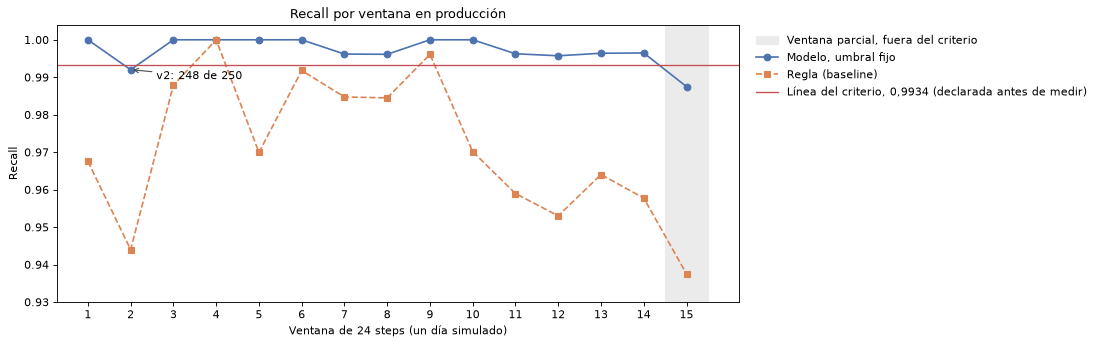

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(14.5, 15.5, color="0.92", zorder=0, label="Ventana parcial, fuera del criterio")
ax.plot(table.index, table["model_recall"], "o-", color=MODEL, label="Modelo, umbral fijo")
ax.plot(table.index, table["rule_recall"], "s--", color=RULE, label="Regla (baseline)")
ax.axhline(
    float(performance.DEGRADATION_LINE),
    color=CUT,
    lw=1.2,
    label="Línea del criterio, 0,9934 (declarada antes de medir)",
)
second = table.loc[2]
ax.annotate(
    f"v2: {second['model_true_positives']:.0f} de {second['positives']:.0f}",
    (2, second["model_recall"]),
    xytext=(2.6, 0.9895),
    arrowprops={"arrowstyle": "->", "color": "0.3"},
)
ax.set_xticks(table.index)
ax.set_ylim(0.93, 1.004)
ax.set_xlabel("Ventana de 24 steps (un día simulado)")
ax.set_ylabel("Recall")
ax.set_title("Recall por ventana en producción")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.show()

**Figura 1.** El modelo queda sobre la línea en 13 de las 14 ventanas completas. Solo la
ventana 2 cae debajo: atrapa 248 de 250 fraudes, recall 0,9920. Una ventana sola es ruido, y el
estado del criterio es **sin alerta**. El modelo pierde a lo sumo 2 fraudes en cualquier día de
producción. La regla queda siempre por debajo del modelo, entre 0,944 y 1,000, y la distancia
entre las dos curvas son los fraudes que el modelo atrapa sin la firma.

Lo que el criterio podía ver: con ~260 fraudes por ventana, un fraude perdido mueve el recall
0,004, más que la dispersión que define la línea. Si el recall verdadero fuera 0,9970 en todas
las ventanas, una alerta saldría por azar con probabilidad 0,302 y una degradación con 0,054.
Que no haya salido ninguna es compatible con un modelo estable; la alerta es un instrumento
ruidoso a esta resolución, y eso estaba medido antes de mirar producción.

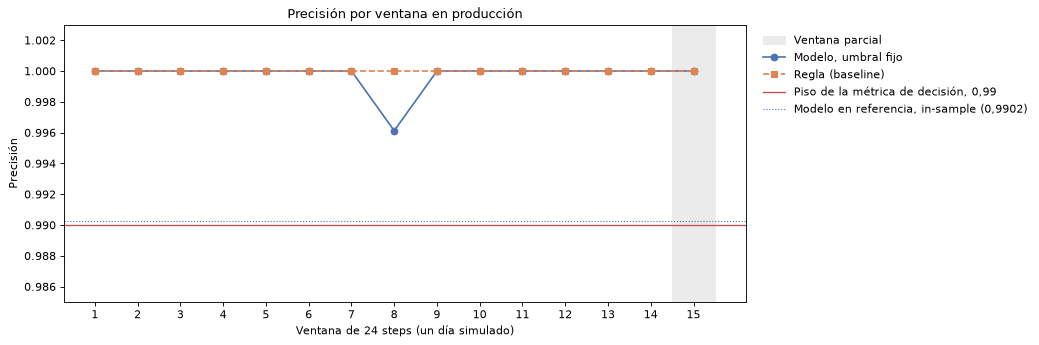

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(14.5, 15.5, color="0.92", zorder=0, label="Ventana parcial")
ax.plot(table.index, table["model_precision"], "o-", color=MODEL, label="Modelo, umbral fijo")
ax.plot(table.index, table["rule_precision"], "s--", color=RULE, label="Regla (baseline)")
ax.axhline(DECISION_PRECISION, color=CUT, lw=1.2, label="Piso de la métrica de decisión, 0,99")
ax.axhline(
    reference_overall["model_precision"],
    color=MODEL,
    lw=1,
    ls=":",
    label="Modelo en referencia, in-sample (0,9902)",
)
ax.set_xticks(table.index)
ax.set_ylim(0.985, 1.003)
ax.set_xlabel("Ventana de 24 steps (un día simulado)")
ax.set_ylabel("Precisión")
ax.set_title("Precisión por ventana en producción")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.show()

**Figura 2.** La regla tiene precisión 1,000 en todas las ventanas. El modelo, en 13 de 14; la
excepción es la ventana 8, con una legítima marcada (0,9961). Todas quedan muy por encima del
piso de 0,99 y de la precisión in-sample del modelo en referencia, 0,9902. **Esa subida no es
mérito del modelo**, y la figura siguiente muestra de dónde sale.

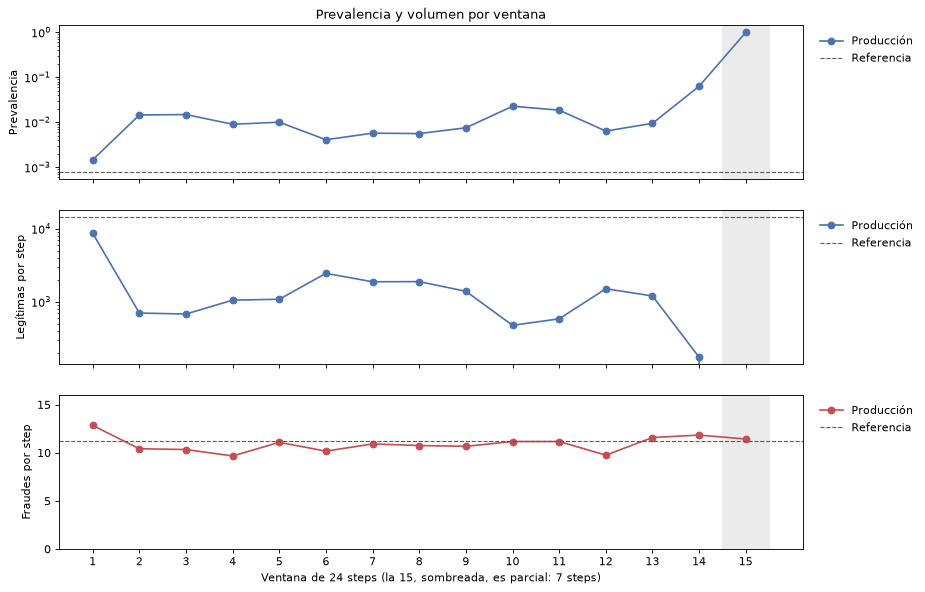

In [10]:
volume = drift.volume_by_window(steps, labels, window_of_row)
reference_volume = drift.volume_by_window(
    reference_rows["step"].to_numpy(), reference_labels, np.zeros(len(reference_labels))
).iloc[0]

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
panels = [
    (table["prevalence"], reference_overall["prevalence"], "Prevalencia", "log", MODEL),
    (
        volume["legitimate_per_step"],
        reference_volume["legitimate_per_step"],
        "Legítimas por step",
        "log",
        LEGIT,
    ),
    (
        volume["frauds_per_step"],
        reference_volume["frauds_per_step"],
        "Fraudes por step",
        "linear",
        FRAUD,
    ),
]
for ax, (series, reference_value, label, scale, color) in zip(axes, panels, strict=True):
    ax.axvspan(14.5, 15.5, color="0.92", zorder=0)
    ax.plot(series.index, series, "o-", color=color, label="Producción")
    ax.axhline(reference_value, color="0.35", ls="--", lw=1, label="Referencia")
    ax.set_yscale(scale)
    ax.set_ylabel(label)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
axes[2].set_ylim(0, 16)
axes[2].set_xticks(table.index)
axes[2].set_xlabel("Ventana de 24 steps (la 15, sombreada, es parcial: 7 steps)")
axes[0].set_title("Prevalencia y volumen por ventana")
plt.show()

**Figura 3: por qué subió la precisión.** El fraude llega a una tasa casi constante, unos 11 por
step en los dos periodos y en todas las ventanas (panel inferior). El volumen legítimo, no: cae
de 14.456 por step en referencia a entre 175 y 8.710 por step en producción (panel del medio,
escala logarítmica; la ventana 15 no tiene punto porque no tiene legítimas). Con el mismo fraude y muchas menos legítimas, la prevalencia se multiplica:
8,4 veces en el agregado, hasta 0,063 en la ventana 14, y 1,0 en la parcial, donde solo hay
fraude.

Al umbral fijo, los verdaderos positivos siguen a la cantidad de fraude y los falsos positivos
siguen al volumen legítimo. Menos legítimas, menos falsos positivos: la precisión sube **por
aritmética de prevalencia**, no porque el modelo discrimine mejor. Si el volumen legítimo
volviera al de referencia, la precisión volvería con él, sin que el modelo cambiara.

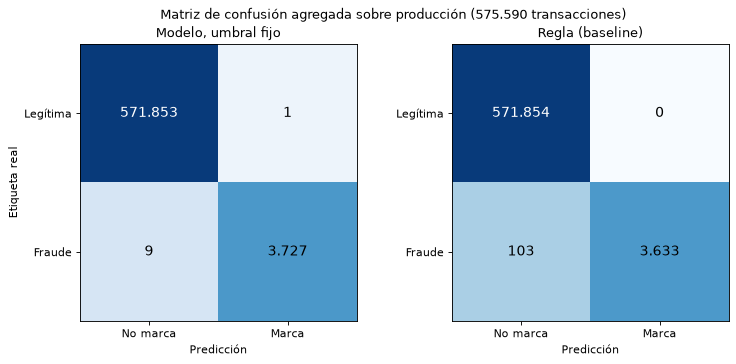

In [11]:
model_counts = performance.confusion(labels, scores >= performance.OPERATING_THRESHOLD)
rule_counts = performance.confusion(labels, rule_flags)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, counts) in zip(
    axes, [("Modelo, umbral fijo", model_counts), ("Regla (baseline)", rule_counts)], strict=True
):
    matrix = np.array(
        [
            [counts.true_negatives, counts.false_positives],
            [counts.false_negatives, counts.true_positives],
        ]
    )
    ax.imshow(np.log10(matrix + 1), cmap="Blues", vmin=0, vmax=6)
    for (row, column), value in np.ndenumerate(matrix):
        color = "white" if value > 100_000 else "black"
        text = f"{value:,}".replace(",", ".")
        ax.text(column, row, text, ha="center", va="center", color=color, fontsize=13)
    ax.set_xticks([0, 1], ["No marca", "Marca"])
    ax.set_yticks([0, 1], ["Legítima", "Fraude"])
    ax.set_xlabel("Predicción")
    ax.set_title(title)
axes[0].set_ylabel("Etiqueta real")
fig.suptitle("Matriz de confusión agregada sobre producción (575.590 transacciones)")
plt.show()

**Figura 4.** Sobre las 575.590 transacciones de producción, el modelo marca 3.728: 3.727
fraudes y una legítima, y deja pasar 9 fraudes. La regla marca 3.633, todas fraude, y deja
pasar 103. El color está en escala logarítmica: la celda de legítimas no marcadas tiene 571.853
filas y no se puede dibujar en la misma escala lineal que la de los falsos positivos.

## 4. Drift

### 4.1 Qué se mide y con qué

Se comparan las 11 features que recibe el modelo, tal como las produce el preprocesamiento del
propio artefacto: las tres monetarias, las cinco columnas one-hot de `type`, la bandera de la
firma, y `hour_sin` y `hour_cos`.

- **PSI es la medida primaria.** Sus bins salen **solo de referencia**: los deciles de
  referencia para las tres monetarias, y un bin por valor para las otras ocho. Ninguna fila de
  producción mueve un borde.
- **Los cortes 0,1 (moderado) y 0,25 (significativo) son una convención**, no se derivaron de
  estos datos. Tienen puntos ciegos medidos, en la sección 4.4.
- **KS se reporta como distancia**: el mayor salto entre las dos distribuciones acumuladas. Su
  p-valor no se calcula en ninguna parte: con 575.590 filas cualquier diferencia es
  significativa, y eso no dice nada de su tamaño.

**Qué significa el drift en cada feature.** En las monetarias, que montos y saldos se movieron.
En los one-hot, que cambió la mezcla de operaciones. La bandera solo la tienen fraudes, así que
su drift sigue a la prevalencia. Y `hour_sin` y `hour_cos` tienen **soporte idéntico por
construcción**: todo step cae en una de las 24 horas, en los dos periodos. Un drift ahí nunca es
un valor que el modelo no vio; solo puede ser otra forma de repartir el volumen de
transacciones sobre las horas del día. Significa otra cosa que en las monetarias.

### 4.2 Primero, el control positivo

Un PSI cercano a 0 sobre datos reales es un control negativo, no evidencia de que nada se
movió: un detector mudo y uno roto se leen igual. Antes de creerle al silencio, el detector
tiene que disparar ante un desplazamiento de magnitud conocida. Los tests versionados
(`tests/test_drift.py`) lo verifican, también a través del artefacto completo; aquí se repite
el caso más simple, para verlo: una normal de referencia contra la misma normal desplazada δ
desviaciones estándar. Para dos normales así, el PSI tiende a δ².

In [12]:
rng = np.random.default_rng(settings.RANDOM_STATE)
synthetic = drift.FeatureProfile.from_reference("x", rng.normal(0, 1, 200_000), discrete=False)
control_rows = []
for shift in (0.0, 0.2, 0.4, 0.8):
    sample = rng.normal(shift, 1, 100_000)
    psi = synthetic.psi(sample)
    control_rows.append(
        {
            "δ": shift,
            "PSI": psi,
            "nivel": drift.psi_level(psi),
            "δ² (teoría)": shift**2,
            "KS": synthetic.ks(sample),
        }
    )
pd.DataFrame(control_rows).set_index("δ")

,PSI,nivel,δ² (teoría),KS
δ,,,,
0,0.000110904,stable,0,0.00317
0.2,0.0386688,stable,0.04,0.081605
0.4,0.150945,moderate,0.16,0.158465
0.8,0.59592,significant,0.64,0.31123


El detector dispara en proporción a lo que se le inyecta: casi nada sin desplazamiento, y cada
vez más con δ, cerca de δ². Cada desplazamiento cae en una banda distinta. Con el instrumento
probado, su lectura sobre producción significa algo.

### 4.3 Producción contra referencia

In [13]:
money = CONFIGURATIONS["full"].money
discrete = [name for name in features.columns if name not in money]
profiles = drift.reference_profiles(reference_features, discrete)
whole = drift.drift_table(profiles, features)
whole

,kind,bins,psi,level,ks
feature,,,,,
amount,continuous,10,0.00342111,stable,0.0212534
oldbalanceOrg,continuous,8,0.00549868,stable,0.0319817
oldbalanceDest,continuous,7,0.00310757,stable,0.0232723
type_CASH_IN,discrete,3,3.75924e-05,stable,0.00254383
type_CASH_OUT,discrete,3,0.00274718,stable,0.0248508
type_DEBIT,discrete,3,0.000170686,stable,0.00108474
type_PAYMENT,discrete,3,0.000996198,stable,0.0149956
type_TRANSFER,discrete,3,0.000491852,stable,0.00622662
amount_equals_origin_balance,discrete,3,0.0118047,stable,0.00555406


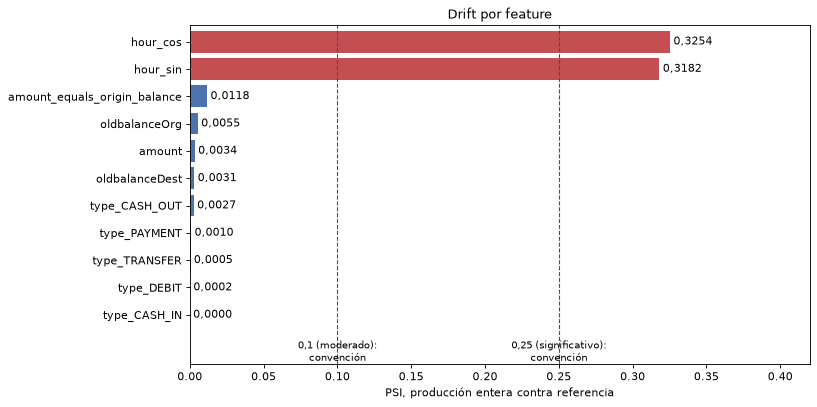

In [14]:
ordered = whole["psi"].sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [CUT if value >= drift.PSI_MODERATE else MODEL for value in ordered]
bars = ax.barh(ordered.index, ordered, color=colors)
ax.bar_label(bars, labels=[f"{value:.4f}".replace(".", ",") for value in ordered], padding=3)
for cut, name in ((drift.PSI_MODERATE, "moderado"), (drift.PSI_SIGNIFICANT, "significativo")):
    ax.axvline(cut, color="0.3", ls="--", lw=1)
    ax.text(
        cut,
        -0.9,
        f"{cut:g} ({name}):\nconvención".replace(".", ","),
        ha="center",
        va="top",
        fontsize=9,
    )
ax.set_xlim(0, 0.42)
ax.set_ylim(-1.8, len(ordered) - 0.4)
ax.set_xlabel("PSI, producción entera contra referencia")
ax.set_title("Drift por feature")
plt.show()

**Figura 5.** Solo driftan las dos features de la hora: PSI 0,32 y 0,33, sobre el corte
significativo. Montos, saldos, mezcla de operaciones y bandera quedan muy por debajo de 0,1: la
mayor es la bandera, con 0,012. El KS de la tabla cuenta lo mismo como distancia: 0,16 y 0,25
para la hora, a lo sumo 0,032 para el resto. Los dos cortes punteados son la convención, no un
umbral calibrado sobre estos datos.

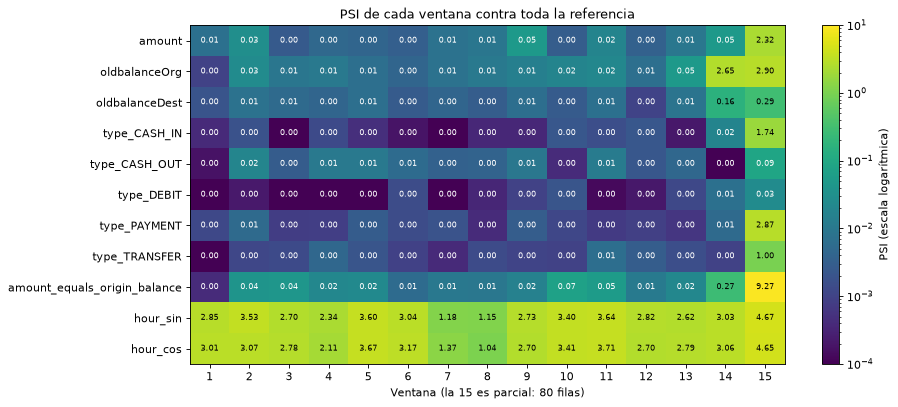

In [15]:
window_psi, window_ks = drift.window_drift(profiles, features, window_of_row)
fig, ax = plt.subplots(figsize=(12, 5.5))
image = ax.imshow(window_psi.T, cmap="viridis", norm=LogNorm(vmin=1e-4, vmax=10), aspect="auto")
for (feature, window), value in np.ndenumerate(window_psi.T.to_numpy()):
    color = "black" if value >= 0.1 else "white"
    ax.text(window, feature, f"{value:.2f}", ha="center", va="center", fontsize=7, color=color)
ax.set_xticks(range(len(window_psi)), [f"{n}" for n in window_psi.index])
ax.set_yticks(range(len(window_psi.columns)), window_psi.columns)
ax.set_xlabel("Ventana (la 15 es parcial: 80 filas)")
ax.set_title("PSI de cada ventana contra toda la referencia")
fig.colorbar(image, ax=ax, label="PSI (escala logarítmica)")
plt.show()

**Figura 6.** Ventana por ventana se ven tres cosas distintas:

- **La hora driftea en todas las ventanas**, con PSI entre 1,0 y 3,7. Una ventana es un día, y
  se compara con el perfil horario acumulado de 400 steps: cada día de producción reparte su
  volumen sobre las horas de una forma muy distinta a ese promedio.
- **La ventana 14 es la única con drift en las monetarias:** `oldbalanceOrg` 2,645 y
  `oldbalanceDest` 0,160, más la bandera, 0,267.
- **La ventana 15 driftea en todo**, pero son 80 filas y las 80 son fraude: su PSI mezcla ruido
  de muestreo con un cambio total de la mezcla de clases (sección 4.4). No se interpreta.

En el resto, montos, saldos, tipos y bandera quedan debajo de 0,1 en todas las ventanas.

### 4.4 Los dos puntos ciegos del PSI, medidos

**Primero: el PSI no es independiente del tamaño de muestra en ventanas chicas.** Para saber
cuánto PSI produce el puro muestreo, se sacan muestras de la propia referencia, que no tienen
drift contra ella, del tamaño de la ventana que se juzga. La tabla da el percentil 95 de 20
muestras por tamaño.

In [16]:
sizes = {
    "80 filas (ventana parcial)": int(table.loc[~table["complete"], "rows"].min()),
    "4.474 filas (la completa más chica)": int(complete["rows"].min()),
}
null = drift.null_psi_quantiles(profiles, reference_features, sizes, derived_seeds(20), 0.95)
null

,80 filas (ventana parcial),4.474 filas (la completa más chica)
amount,0.208364,0.00263018
oldbalanceOrg,0.256595,0.00281619
oldbalanceDest,0.14927,0.00318355
type_CASH_IN,0.0445696,0.000987791
type_CASH_OUT,0.0304197,0.000626649
type_DEBIT,0.0263125,0.000424701
type_PAYMENT,0.0544227,0.000455391
type_TRANSFER,0.0735458,0.000529578
amount_equals_origin_balance,0.00553364,0.000686489
hour_sin,0.678843,0.00624851


Con 4.474 filas, el ruido queda en 0,0062 como máximo, al menos 16 veces por debajo del corte
de 0,1: en las 14 ventanas completas el corte significa lo mismo, y la premisa del ADR 0012 se
cumple. **Con 80 filas no:** el puro muestreo llega a 0,68 en la hora y a 0,26 en
`oldbalanceOrg`, por encima de los cortes. Por eso la ventana parcial no se interpreta como
drift.

**Segundo: el PSI no ve el drift de una categoría rara.** La tabla siguiente son las
proporciones que compara el PSI para la bandera de la firma.

In [17]:
flag = "amount_equals_origin_balance"
shares = drift.bin_shares(profiles[flag], features[flag].to_numpy())
print(f"PSI de la bandera: {whole.loc[flag, 'psi']:.4f} ({whole.loc[flag, 'level']})")
shares

PSI de la bandera: 0.0118 (stable)


,reference,sample
bin,,
0,0.999242,0.993688
1,0.000757729,0.00631178
NaN,0,0


La bandera pasa de estar en el 0,076% de las filas al 0,631%: **8,3 veces más**. Su PSI es
0,012, que se lee como "estable". El PSI pesa diferencias absolutas de proporción, y una
categoría del 0,1% no tiene masa para moverlo, aunque se multiplique. Una prevalencia que
importa no se monitorea a través del PSI: se mide directo, como la prevalencia de la figura 3.

### 4.5 La hora, la feature que más se movió

`hour_sin` y `hour_cos` son la hora del día, `step % 24`, puesta sobre un círculo. Su drift es,
entonces, un cambio en la distribución de las transacciones por hora. La figura la separa por
clase.

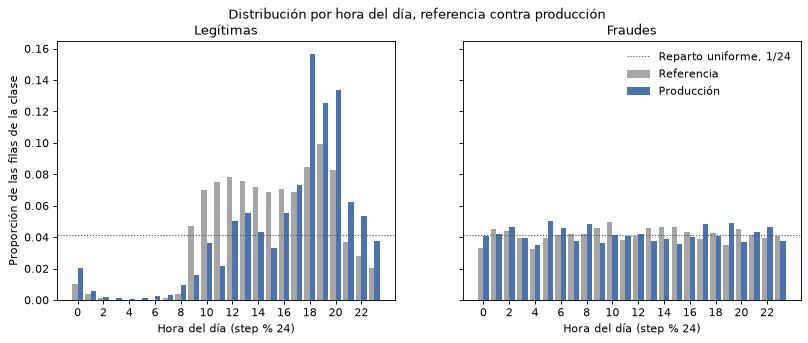

In [18]:
hours = {
    "Referencia": drift.hour_profile(reference_rows["step"].to_numpy(), reference_labels),
    "Producción": drift.hour_profile(steps, labels),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
width = 0.42
for ax, (column, title) in zip(
    axes, [("legitimate", "Legítimas"), ("fraud", "Fraudes")], strict=True
):
    for offset, (period, color) in zip(
        (-width / 2, width / 2), [("Referencia", "0.65"), ("Producción", MODEL)], strict=True
    ):
        profile = hours[period][column]
        ax.bar(profile.index + offset, profile, width=width, color=color, label=period)
    ax.axhline(1 / 24, color="0.3", ls=":", lw=1, label="Reparto uniforme, 1/24")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hora del día (step % 24)")
    ax.set_title(title)
axes[0].set_ylabel("Proporción de las filas de la clase")
axes[1].legend(frameon=False)
fig.suptitle("Distribución por hora del día, referencia contra producción")
plt.show()

**Figura 7.** Los fraudes se reparten casi uniformes sobre las 24 horas, en los dos periodos:
el agente de fraude ignora la hora. Las legítimas no. En referencia se concentran entre las 9 y
las 20 horas; en producción el volumen se corre hacia la tarde: las 18, 19 y 20 horas juntan el
42% de las legítimas, contra el 27% en referencia, y la mañana se vacía. Ese corrimiento es todo
el drift de la hora.

El modelo apenas usa la hora: permutarla le cuesta 11,7 y 15,3 fraudes en referencia, por debajo
de la significancia práctica (`docs/analysis/interpretability.md`). Un drift significativo en una
feature que el modelo casi no usa no tiene por qué mover el desempeño.

### 4.6 La ventana 14: un cambio en las legítimas, no en la mezcla

La ventana 14 tiene 6,3% de fraude, y una feature que distingue fraude de legítima driftea con
solo cambiar la mezcla de clases. Para separar las dos cosas, se comparan solo las legítimas de
cada ventana contra las legítimas de referencia.

In [19]:
legitimate = labels == 0
reference_legitimate = reference_labels == 0
legitimate_profiles = drift.reference_profiles(reference_features[reference_legitimate], discrete)
legitimate_psi, _ = drift.window_drift(
    legitimate_profiles, features[legitimate], window_of_row[legitimate]
)
pd.DataFrame(
    {
        "todas las filas": window_psi.loc[14, [*money, flag]],
        "solo legítimas": legitimate_psi.loc[14, [*money, flag]],
    }
)

,todas las filas,solo legítimas
amount,0.0505905,0.115396
oldbalanceOrg,2.64548,3.72151
oldbalanceDest,0.160021,0.155987
amount_equals_origin_balance,0.266984,0


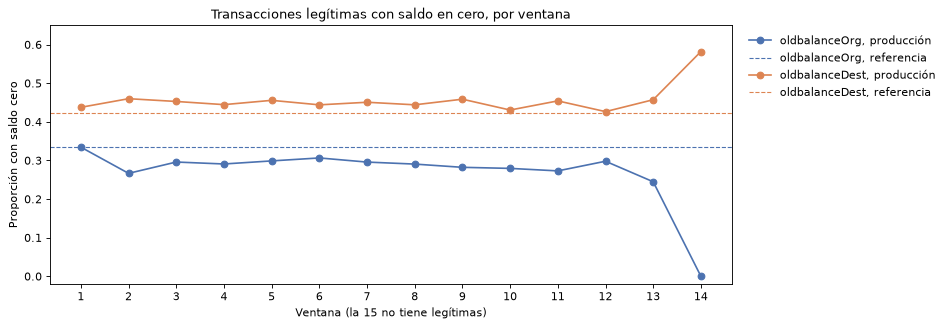

In [20]:
zeros = drift.zero_shares(rows[legitimate], money, window_of_row[legitimate])
reference_zeros = drift.zero_shares(
    reference_rows[reference_legitimate], money, np.zeros(int(reference_legitimate.sum()))
).iloc[0]
fig, ax = plt.subplots(figsize=(11, 4.2))
for column, color in (("oldbalanceOrg", MODEL), ("oldbalanceDest", RULE)):
    ax.plot(zeros.index, zeros[column], "o-", color=color, label=f"{column}, producción")
    ax.axhline(reference_zeros[column], color=color, ls="--", lw=1, label=f"{column}, referencia")
ax.set_xticks(zeros.index)
ax.set_ylim(-0.02, 0.65)
ax.set_xlabel("Ventana (la 15 no tiene legítimas)")
ax.set_ylabel("Proporción con saldo cero")
ax.set_title("Transacciones legítimas con saldo en cero, por ventana")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.show()

**Figura 8.** Entre las legítimas solas, `oldbalanceOrg` sigue drifteando en la ventana 14 (PSI
3,72): no es la mezcla de clases. Lo que se movió es concreto. En referencia, un tercio de las
legítimas sale de una cuenta con saldo cero (0,334), y en las ventanas 1 a 13 entre 0,245 y
0,334. **En la ventana 14, ninguna:** el generador dejó de producir transacciones legítimas desde
cuentas vacías, de golpe. A la vez, los destinos con saldo cero suben de ~0,45 a 0,58.

La bandera, en cambio, es pura mezcla: ninguna legítima la tiene, en ningún periodo, y entre las
legítimas su PSI es 0.

## 5. Interpretación

**La precisión subió por aritmética de prevalencia, no por mérito.** El modelo pasa de 0,9902
in-sample en referencia a 0,9997 en producción. Al umbral fijo, los falsos positivos siguen al
volumen legítimo, que cayó 8,7 veces, mientras el fraude por step quedó casi igual (figura 3).
La cifra que habla del modelo es el recall: 0,9976 en producción contra 0,9970 ± 0,0036 en la
validación temporal de referencia. **El modelo no se degradó.**

**La cola de revisión.** Cada ventana es un día simulado. El modelo manda a revisión entre 232
y 308 transacciones por día, unas 261 en promedio, y en catorce días solo una de ellas fue
legítima. Cada falso positivo es una revisión que no encuentra nada, es decir, horas de analista.
Pero **el tiempo por revisión no está medido** en este proyecto, así que las horas no se
afirman: con *t* minutos por caso, la cola cuesta unos 261·*t* minutos por día, y los falsos
positivos, *t* minutos en dos semanas.

**La regla se sostiene, y eso habla del generador.** Precisión 1,000 sobre un periodo nuevo: la
firma es del agente de fraude del simulador, que sigue vaciando cuentas a una tasa constante e
indiferente a la hora, encima de una población legítima que cambia de volumen y de horario. En
datos reales no habría esa garantía: un atacante real se adapta a la regla que lo atrapa.

**El drift no coincide con el desempeño.**

- La ventana con el único drift de covariables, la **14**, no movió el desempeño: recall 0,9965,
  un fraude perdido de 284, y ningún falso positivo.
- La única ventana debajo de la línea, la **2**, cae **sin drift propio**: la hora driftea como en
  todas, y sus monetarias, su bandera y sus tipos quedan debajo de 0,04.
- **Dos cosas en la misma ventana no son causa.** Aun si una caída de recall y un drift hubieran
  coincidido, eso no probaría que el drift la causó: los dos pueden venir de un tercer factor,
  como el colapso del volumen legítimo, que mueve a la vez la mezcla, el perfil horario y la
  prevalencia; o de la suerte, cuando una ventana cae debajo de la línea por azar con
  probabilidad de hasta 0,21. Separar causa de coincidencia exige intervenir, y un monitoreo solo
  observa.

## 6. Qué haría falta para llevar esto a producción real

**Etiquetas que llegan tarde.** Aquí cada ventana conoce su fraude al cerrarse. En una operación
real la etiqueta llega días o semanas después, con el contracargo, y el monitoreo de desempeño
iría atrasado. El de drift no necesita etiquetas: avisaría primero, y el desempeño confirmaría
después.

**Alertas.**

- El criterio de dos niveles, tal como está, con su tasa de falsa alarma declarada: a esta
  resolución una alerta sale por azar 3 de cada 10 veces. Ventanas más largas, o exigir la
  degradación y no la alerta para actuar, bajan esa tasa a costa de reaccionar más tarde.
- El drift, con los cortes por convención, pero leído contra su nulo al tamaño de la ventana, y
  nunca sobre ventanas chicas.
- La prevalencia, medida directo y no a través del PSI.
- **La regla como canario, por sus dos cifras.** Su recall vigila al atacante: si cae, el
  agente dejó de vaciar cuentas y el modelo pierde el apoyo de la firma. Su precisión 1,000
  vigila a las legítimas: si cae, algo legítimo empezó a vaciar cuentas y la firma dejó de
  ser exclusiva del fraude. Las dos cosas importan más que cualquier PSI.

**Reentrenamiento.** Lo dispara el criterio de degradación, no el drift solo: la hora driftea
todos los días sin mover el desempeño. Se reentrena con el mismo arnés temporal, y el umbral
nuevo se elige sobre un periodo etiquetado distinto del que después se monitorea, por la misma
razón de la sección 2. La versión nueva se registra en el Model Registry y se compara con la
actual sobre las mismas ventanas antes de reemplazarla.

**Lo que no se midió:**

- el tiempo de revisión por caso, y con él el costo en horas;
- el retraso de las etiquetas;
- la adaptación de un atacante real;
- los 9 fraudes que el modelo pierde en producción;
- la calibración de las probabilidades: el Brier lo domina la mayoría legítima;
- nada más allá del step 743, donde termina la simulación.

*Nota de estado (2026-10-22): este pasaje decía que el canario de un cambio del agente de fraude
es la **precisión** de la regla. Es al revés: si el agente deja de vaciar cuentas, cae el
**recall** de la regla; su precisión solo cae si alguna legítima empieza a vaciarlas. El mismo
error apareció en el borrador del Model Card de la fase 5 y se corrigió allí
(`docs/MODEL_CARD.md`, secciones 4 y 9).*